<a href="https://colab.research.google.com/github/KyleRed16/Herbert-vs-Allen/blob/main/Phase_1_Expected_EPA_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 1: Context-Adjusted Quarterback Performance

## Project Objective

Develop a predictive model using NFL play-by-play data to estimate expected EPA based on pre-snap game context.

The goal is to evaluate Justin Herbert and Josh Allen relative to the expected performance of an average quarterback in comparable situations.

## Research Question

How much value do Justin Herbert and Josh Allen generate above or below the expected EPA of a quarterback facing similar situations?

In [1]:
!pip install nflreadpy

import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pbp = nfl.load_pbp(
    seasons=[2021, 2022, 2023, 2024, 2025]
).to_pandas()

pbp = pbp[
    pbp["season_type"].eq("REG")
].copy()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [nflreadpy]


In [2]:
print("Dataset shape:", pbp.shape)
print("Number of columns:", len(pbp.columns))
print("Seasons:", sorted(pbp["season"].unique()))
print("Season types:", pbp["season_type"].unique())

Dataset shape: (235933, 372)
Number of columns: 372
Seasons: [np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]
Season types: ['REG']


# 1. Constructing and Validating The Modeling Population

In [3]:
potential_features = [
    "down",
    "ydstogo",
    "yardline_100",
    "game_seconds_remaining",
    "half_seconds_remaining",
    "score_differential",
    "posteam",
    "defteam",
    "season",
    "week",
    "qtr",
    "shotgun",
    "no_huddle",
    "qb_dropback",
    "qb_epa",
    "epa",
    "play_type",
    "passer_player_name",
    "rusher_player_name"
]

for col in potential_features:
    if col in pbp.columns:
        print(f"{col}: {pbp[col].dtype}")
    else:
        print(f"{col}: NOT FOUND")

down: float64
ydstogo: float64
yardline_100: float64
game_seconds_remaining: float64
half_seconds_remaining: float64
score_differential: float64
posteam: object
defteam: object
season: int32
week: int32
qtr: float64
shotgun: float64
no_huddle: float64
qb_dropback: float64
qb_epa: float64
epa: float64
play_type: object
passer_player_name: object
rusher_player_name: object


In [4]:
feature_check = [
    "down",
    "ydstogo",
    "yardline_100",
    "game_seconds_remaining",
    "half_seconds_remaining",
    "score_differential",
    "posteam",
    "defteam",
    "season",
    "week",
    "qtr",
    "shotgun",
    "no_huddle",
    "qb_epa"
]

missing_summary = pd.DataFrame({
    "missing_count": pbp[feature_check].isna().sum(),
    "missing_percentage": (
        pbp[feature_check].isna().mean() * 100
    ).round(2)
})

missing_summary

,missing_count,missing_percentage
down,37699,15.98
ydstogo,0,0.00
yardline_100,16826,7.13
game_seconds_remaining,17,0.01
half_seconds_remaining,17,0.01
score_differential,12895,5.47
posteam,12895,5.47
defteam,12895,5.47
season,0,0.00
week,0,0.00


In [5]:
missing_down = pbp[pbp["down"].isna()]

print("Plays with missing down:", len(missing_down))

print("\nPlay types:")
print(missing_down["play_type"].value_counts(dropna=False))

print("\nQB EPA availability:")
print(missing_down["qb_epa"].notna().value_counts())

print("\nMissing QB EPA by play type:")
print(
    pbp[pbp["qb_epa"].isna()]["play_type"]
    .value_counts(dropna=False)
)

Plays with missing down: 37699

Play types:
play_type
kickoff        13784
no_play        10219
None            6895
extra_point     6138
pass             475
run              188
Name: count, dtype: int64

QB EPA availability:
qb_epa
True     34981
False     2718
Name: count, dtype: int64

Missing QB EPA by play type:
play_type
None    2718
Name: count, dtype: int64


In [6]:
print("QB EPA summary:")
print(pbp["qb_epa"].describe())

print("\nQB EPA by play type:")
print(
    pbp.groupby("play_type", dropna=False)["qb_epa"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
)

print("\nRows with QB EPA but no play type:")
print(
    pbp[
        pbp["qb_epa"].notna() &
        pbp["play_type"].isna()
    ][
        ["season", "week", "posteam", "defteam",
         "down", "qb_epa", "epa"]
    ].head(10)
)

QB EPA summary:
count    233215.000000
mean         -0.003409
std           1.046792
min         -11.086635
25%          -0.468752
50%           0.000000
75%           0.429746
max           7.482049
Name: qb_epa, dtype: float64

QB EPA by play type:
             count      mean    median
play_type                             
pass         97026  0.026059 -0.175056
run          71255 -0.011700 -0.123587
no_play      22533 -0.009230 -0.000000
kickoff      13784 -0.017983 -0.000000
punt         10520 -0.093568 -0.101154
extra_point   6138 -0.001864  0.040000
field_goal    5352  0.019277  0.197627
NaN           4177 -0.000990 -0.000000
qb_kneel      2085 -0.538475  0.000000
qb_spike       345 -0.042067 -0.075841

Rows with QB EPA but no play type:
     season  week posteam defteam  down  qb_epa  epa
0      2021     1    None    None   NaN     0.0  0.0
45     2021     1     ARI     TEN   NaN    -0.0 -0.0
150    2021     1     ARI     TEN   NaN    -0.0 -0.0
180    2021     1    None    None

In [7]:
print("Passer identified:", pbp["passer_player_name"].notna().sum())

print("Rusher identified:", pbp["rusher_player_name"].notna().sum())

print("\nQB dropback values:")
print(pbp["qb_dropback"].value_counts(dropna=False))

print("\nQB scramble values:")
print(pbp["qb_scramble"].value_counts(dropna=False))

print("\nRush attempt values:")
print(pbp["rush_attempt"].value_counts(dropna=False))

Passer identified: 97373
Rusher identified: 73345

QB dropback values:
qb_dropback
0.0    127012
1.0    102026
NaN      6895
Name: count, dtype: int64

QB scramble values:
qb_scramble
0.0    230577
1.0      5356
Name: count, dtype: int64

Rush attempt values:
rush_attempt
0.0    155415
1.0     73345
NaN      7173
Name: count, dtype: int64


In [8]:
is_dropback = pbp["qb_dropback"].eq(1)

is_scramble = (
    pbp["play_type"].eq("run") &
    pbp["qb_scramble"].eq(1)
)

is_designed_run = (
    pbp["play_type"].eq("run") &
    pbp["rusher_player_name"].notna() &
    pbp["qb_scramble"].eq(0) &
    pbp["rush_attempt"].eq(1)
)

is_qb_play = (
    is_dropback |
    is_scramble |
    is_designed_run
)

print("Dropbacks:", is_dropback.sum())
print("Scrambles:", is_scramble.sum())
print("Designed runs:", is_designed_run.sum())
print("Qualifying QB plays:", is_qb_play.sum())

print("\nOverlapping categories:")
print("Dropbacks and scrambles:", (is_dropback & is_scramble).sum())
print("Dropbacks and designed runs:", (is_dropback & is_designed_run).sum())
print("Scrambles and designed runs:", (is_scramble & is_designed_run).sum())

Dropbacks: 102026
Scrambles: 5000
Designed runs: 66255
Qualifying QB plays: 168281

Overlapping categories:
Dropbacks and scrambles: 5000
Dropbacks and designed runs: 0
Scrambles and designed runs: 0


In [9]:
designed_runs = pbp[is_designed_run].copy()

print("Unique designed-run rushers:",
      designed_runs["rusher_player_name"].nunique())

print("\nMost frequent designed-run rushers:")
print(
    designed_runs["rusher_player_name"]
    .value_counts()
    .head(20)
)

print("\nDesigned runs by team:")
print(
    designed_runs["posteam"]
    .value_counts()
    .head(10)
)

Unique designed-run rushers: 714

Most frequent designed-run rushers:
rusher_player_name
D.Henry         1481
B.Robinson      1470
J.Taylor        1361
S.Barkley       1334
J.Jacobs        1328
J.Williams      1196
N.Harris        1113
T.Pollard       1079
J.Mixon         1008
A.Kamara        1005
D.Montgomery     991
C.McCaffrey      978
D.Swift          956
T.Etienne        920
A.Jones          913
C.Hubbard        891
J.Conner         866
K.Williams       843
J.Cook           842
R.Stevenson      837
Name: count, dtype: int64

Designed runs by team:
posteam
PHI    2395
BAL    2305
ATL    2287
DET    2268
SF     2235
DAL    2186
IND    2182
GB     2174
CHI    2173
PIT    2154
Name: count, dtype: int64


In [10]:
position_columns = [
    "rusher_player_name",
    "rusher_player_id",
    "rusher_position",
    "passer_player_name",
    "passer_player_id",
    "passer_position"
]

for col in position_columns:
    if col in pbp.columns:
        print(f"{col}: FOUND")
    else:
        print(f"{col}: NOT FOUND")

rusher_player_name: FOUND
rusher_player_id: FOUND
rusher_position: NOT FOUND
passer_player_name: FOUND
passer_player_id: FOUND
passer_position: NOT FOUND


In [11]:
players = nfl.load_players().to_pandas()

print("Player dataset shape:", players.shape)

print("\nAvailable columns:")
print(players.columns.tolist())

Player dataset shape: (24871, 39)

Available columns:
['gsis_id', 'display_name', 'common_first_name', 'first_name', 'last_name', 'short_name', 'football_name', 'suffix', 'esb_id', 'nfl_id', 'pfr_id', 'pff_id', 'otc_id', 'espn_id', 'smart_id', 'birth_date', 'position_group', 'position', 'ngs_position_group', 'ngs_position', 'height', 'weight', 'headshot', 'college_name', 'college_conference', 'jersey_number', 'rookie_season', 'last_season', 'latest_team', 'status', 'ngs_status', 'ngs_status_short_description', 'years_of_experience', 'pff_position', 'pff_status', 'draft_year', 'draft_round', 'draft_pick', 'draft_team']


In [15]:
print("Quarterback designed runs:",
    designed_runs["rusher_position"].eq("QB").sum()
)

Quarterback designed runs: 4269


In [17]:
is_dropback = pbp["qb_dropback"].eq(1)

is_scramble = (
    pbp["play_type"].eq("run") &
    pbp["qb_scramble"].eq(1)
)

is_qb_designed_run = (
    pbp["play_type"].eq("run") &
    pbp["rush_attempt"].eq(1) &
    pbp["qb_scramble"].eq(0) &
    pbp["rusher_player_id"].map(position_lookup).eq("QB")
)

is_qb_play = (
    is_dropback |
    is_scramble |
    is_qb_designed_run
)

qb_league = pbp[is_qb_play].copy()

print("Dropbacks:", is_dropback.sum())
print("Scrambles:", is_scramble.sum())
print("Designed QB runs:", is_qb_designed_run.sum())
print("Total qualifying plays:", len(qb_league))

print("\nMissing QB EPA:", qb_league["qb_epa"].isna().sum())
print("Unique quarterbacks:",
      qb_league["passer_player_id"].nunique() +
      qb_league.loc[
          qb_league["passer_player_id"].isna(),
          "rusher_player_id"
      ].nunique())

Dropbacks: 102026
Scrambles: 5000
Designed QB runs: 4269
Total qualifying plays: 106295

Missing QB EPA: 0
Unique quarterbacks: 392


In [18]:
qb_league["qb_player_id"] = (
    qb_league["passer_player_id"]
    .combine_first(qb_league["rusher_player_id"])
)

qb_league["qb_position"] = (
    qb_league["qb_player_id"].map(position_lookup)
)

print("Missing QB identities:", qb_league["qb_player_id"].isna().sum())

print("\nPosition distribution:")
print(qb_league["qb_position"].value_counts(dropna=False))

print("\nUnique QB identities:")
print(qb_league["qb_player_id"].nunique())

print("\nPlays by season:")
print(qb_league.groupby("season").size())

Missing QB identities: 0

Position distribution:
qb_position
QB     105871
TE        213
WR        125
P          39
RB         39
DB          2
LB          2
K           1
FB          1
SAF         1
OT          1
Name: count, dtype: int64

Unique QB identities:
259

Plays by season:
season
2021    21739
2022    21291
2023    21619
2024    21111
2025    20535
dtype: int64


In [19]:
print("Position by play category:")

for category, mask in {
    "Dropbacks": is_dropback,
    "Scrambles": is_scramble,
    "Designed QB runs": is_qb_designed_run
}.items():

    category_data = qb_league.loc[mask]

    print(f"\n{category}:")
    print(
        category_data["qb_position"]
        .value_counts(dropna=False)
    )

Position by play category:

Dropbacks:
qb_position
QB     101602
TE        213
WR        125
P          39
RB         39
DB          2
LB          2
K           1
FB          1
SAF         1
OT          1
Name: count, dtype: int64

Scrambles:
qb_position
QB    4968
TE      19
WR      13
Name: count, dtype: int64

Designed QB runs:
qb_position
QB    4269
Name: count, dtype: int64


In [20]:
qb_league = qb_league[
    qb_league["qb_position"].eq("QB")
].copy()

print("Final qualifying QB plays:", len(qb_league))

print("\nUnique quarterbacks:",
      qb_league["qb_player_id"].nunique())

print("\nPosition distribution:")
print(qb_league["qb_position"].value_counts())

print("\nMissing QB EPA:",
      qb_league["qb_epa"].isna().sum())

print("\nPlays by season:")
print(qb_league.groupby("season").size())

Final qualifying QB plays: 105871

Unique quarterbacks: 135

Position distribution:
qb_position
QB    105871
Name: count, dtype: int64

Missing QB EPA: 0

Plays by season:
season
2021    21517
2022    21231
2023    21554
2024    21068
2025    20501
dtype: int64


# 2.

In [21]:
print("QB EPA distribution:")
print(qb_league["qb_epa"].describe())

print("\nQB EPA percentiles:")
print(
    qb_league["qb_epa"].quantile(
        [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

QB EPA distribution:
count    105871.000000
mean          0.042785
std           1.314951
min         -11.086635
25%          -0.633923
50%          -0.132040
75%           0.781163
max           7.482049
Name: qb_epa, dtype: float64

QB EPA percentiles:
0.01   -4.003467
0.05   -1.658558
0.25   -0.633923
0.50   -0.132040
0.75    0.781163
0.95    2.208700
0.99    3.540053
Name: qb_epa, dtype: float64


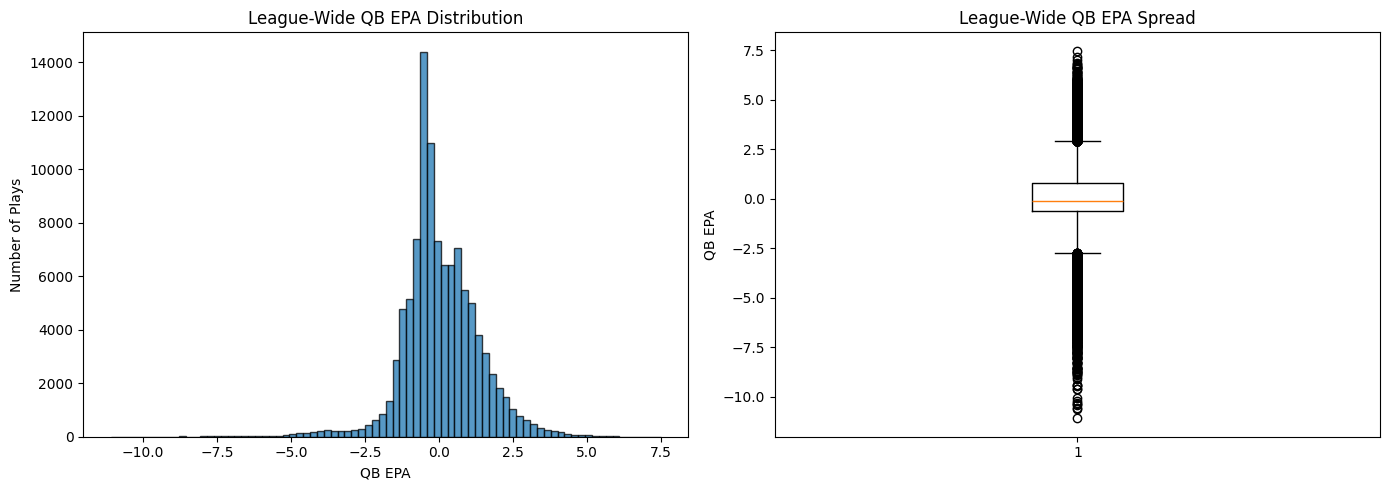

In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    qb_league["qb_epa"],
    bins=80,
    edgecolor="black",
    alpha=0.75
)

axes[0].set_title("League-Wide QB EPA Distribution")
axes[0].set_xlabel("QB EPA")
axes[0].set_ylabel("Number of Plays")

axes[1].boxplot(
    qb_league["qb_epa"],
    vert=True,
    showfliers=True
)

axes[1].set_title("League-Wide QB EPA Spread")
axes[1].set_ylabel("QB EPA")

plt.tight_layout()
plt.show()

In [24]:
print("Play type distribution:")

print(
    qb_league["play_type"]
    .value_counts(dropna=False)
)

print("\nPercentage of plays with zero QB EPA:")

print(
    (qb_league["qb_epa"].eq(0).mean() * 100).round(2),
    "%"
)

print("\nQB EPA by play type:")

print(
    qb_league.groupby("play_type", dropna=False)["qb_epa"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
)

Play type distribution:
play_type
pass    96634
run      9237
Name: count, dtype: int64

Percentage of plays with zero QB EPA:
0.0 %

QB EPA by play type:
           count      mean    median
play_type                           
pass       96634  0.026412 -0.174148
run         9237  0.214065  0.230780


In [25]:
candidate_features = [
    "down",
    "ydstogo",
    "yardline_100",
    "game_seconds_remaining",
    "half_seconds_remaining",
    "score_differential",
    "posteam",
    "defteam",
    "season",
    "week",
    "qtr",
    "shotgun",
    "no_huddle",
    "qb_epa"
]

feature_check = pd.DataFrame({
    "missing_count": qb_league[candidate_features].isna().sum(),
    "missing_percentage": (
        qb_league[candidate_features].isna().mean() * 100
    ).round(2)
})

feature_check

,missing_count,missing_percentage
down,523,0.49
ydstogo,0,0.00
yardline_100,0,0.00
game_seconds_remaining,0,0.00
half_seconds_remaining,0,0.00
score_differential,0,0.00
posteam,0,0.00
defteam,0,0.00
season,0,0.00
week,0,0.00


In [26]:
missing_down_plays = qb_league[
    qb_league["down"].isna()
].copy()

print("Missing-down play types:")
print(missing_down_plays["play_type"].value_counts())

print("\nQB dropback status:")
print(missing_down_plays["qb_dropback"].value_counts(dropna=False))

print("\nQB spike status:")
print(missing_down_plays["qb_spike"].value_counts(dropna=False))

print("\nQB EPA summary:")
print(missing_down_plays["qb_epa"].describe())

print("\nExample observations:")
print(
    missing_down_plays[
        ["season", "week", "qtr", "play_type",
         "qb_dropback", "qb_spike", "qb_epa"]
    ].head(10)
)

Missing-down play types:
play_type
pass    463
run      60
Name: count, dtype: int64

QB dropback status:
qb_dropback
1.0    463
0.0     60
Name: count, dtype: int64

QB spike status:
qb_spike
0.0    523
Name: count, dtype: int64

QB EPA summary:
count    523.000000
mean      -0.030249
std        1.013613
min       -2.960000
25%       -0.960000
50%       -0.940000
75%        1.040000
max        1.060000
Name: qb_epa, dtype: float64

Example observations:
      season  week  qtr play_type  qb_dropback  qb_spike  qb_epa
683     2021     1  4.0      pass          1.0       0.0   -0.94
2092    2021     1  3.0       run          0.0       0.0    1.06
2131    2021     1  4.0      pass          1.0       0.0   -0.94
2671    2021     1  4.0       run          0.0       0.0   -0.94
2851    2021     1  4.0      pass          1.0       0.0    1.06
2859    2021     1  4.0      pass          1.0       0.0    1.06
3010    2021     2  3.0       run          0.0       0.0    1.06
3721    2021     2  4

In [27]:
print("Two-point attempt distribution:")

print(
    missing_down_plays["two_point_attempt"]
    .value_counts(dropna=False)
)

print("\nTwo-point attempts across all QB plays:")

print(
    qb_league["two_point_attempt"]
    .value_counts(dropna=False)
)

print("\nExample play descriptions:")

print(
    missing_down_plays[
        ["play_type", "two_point_attempt",
         "desc", "qb_epa"]
    ].head(15).to_string(index=False)
)

Two-point attempt distribution:
two_point_attempt
1.0    523
Name: count, dtype: int64

Two-point attempts across all QB plays:
two_point_attempt
0.0    105348
1.0       523
Name: count, dtype: int64

Example play descriptions:
play_type  two_point_attempt                                                                                                                                                                                desc  qb_epa
     pass                1.0             TWO-POINT CONVERSION ATTEMPT. 15-P.Mahomes pass to 25-C.Edwards-Helaire is incomplete. ATTEMPT FAILS. Penalty on KC-52-C.Humphrey, Ineligible Downfield Pass, declined.   -0.94
      run                1.0                                                                                                        TWO-POINT CONVERSION ATTEMPT. 2-Z.Wilson rushes right end. ATTEMPT SUCCEEDS.    1.06
     pass                1.0                                                                                            T

In [28]:
qb_model_data = qb_league[
    qb_league["two_point_attempt"].eq(0)
].copy()

print("Original QB plays:", len(qb_league))
print("Excluded two-point attempts:",
      len(qb_league) - len(qb_model_data))

print("Final modeling observations:", len(qb_model_data))

print("\nMissing values:")
print(
    qb_model_data[
        ["down", "ydstogo", "yardline_100", "qb_epa"]
    ].isna().sum()
)

print("\nPlay type distribution:")
print(qb_model_data["play_type"].value_counts())

Original QB plays: 105871
Excluded two-point attempts: 523
Final modeling observations: 105348

Missing values:
down            0
ydstogo         0
yardline_100    0
qb_epa          0
dtype: int64

Play type distribution:
play_type
pass    96171
run      9177
Name: count, dtype: int64


In [29]:
print("Average QB EPA:", qb_model_data["qb_epa"].mean())
print("Median QB EPA:", qb_model_data["qb_epa"].median())

print("\nAverage EPA by play type:")
print(
    qb_model_data.groupby("play_type")["qb_epa"]
    .agg(["count", "mean", "median"])
)

Average QB EPA: 0.043147110676293766
Median QB EPA: -0.13142411119993114

Average EPA by play type:
           count      mean    median
play_type                           
pass       96171  0.026942 -0.173343
run         9177  0.212969  0.228241


In [30]:
candidate_features = [
    "down",
    "ydstogo",
    "yardline_100",
    "game_seconds_remaining",
    "half_seconds_remaining",
    "score_differential",
    "qtr",
    "shotgun",
    "no_huddle",
    "play_type"
]

qb_model_data[candidate_features].info()

<class 'pandas.core.frame.DataFrame'>
Index: 105348 entries, 3 to 244962
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   down                    105348 non-null  float64
 1   ydstogo                 105348 non-null  float64
 2   yardline_100            105348 non-null  float64
 3   game_seconds_remaining  105348 non-null  float64
 4   half_seconds_remaining  105348 non-null  float64
 5   score_differential      105348 non-null  float64
 6   qtr                     105348 non-null  float64
 7   shotgun                 105348 non-null  float64
 8   no_huddle               105348 non-null  float64
 9   play_type               105348 non-null  object 
dtypes: float64(9), object(1)
memory usage: 8.8+ MB


In [32]:
print("Down:")
print(qb_model_data["down"].value_counts().sort_index())

print("\nQuarter:")
print(qb_model_data["qtr"].value_counts().sort_index())

print("\nShotgun:")
print(qb_model_data["shotgun"].value_counts())

print("\nNo huddle:")
print(qb_model_data["no_huddle"].value_counts())

print("\nNumerical feature summaries:")
print(
    qb_model_data[
        [
            "ydstogo",
            "yardline_100",
            "game_seconds_remaining",
            "half_seconds_remaining",
            "score_differential"
        ]
    ].describe()
)

Down:
down
1.0    38039
2.0    35377
3.0    28918
4.0     3014
Name: count, dtype: int64

Quarter:
qtr
1.0    22408
2.0    30080
3.0    22850
4.0    29296
5.0      714
Name: count, dtype: int64

Shotgun:
shotgun
1.0    87299
0.0    18049
Name: count, dtype: int64

No huddle:
no_huddle
0.0    92441
1.0    12907
Name: count, dtype: int64

Numerical feature summaries:
             ydstogo   yardline_100  game_seconds_remaining  \
count  105348.000000  105348.000000           105348.000000   
mean        8.722301      50.973089             1699.441651   
std         4.064483      23.581226             1042.309414   
min         1.000000       1.000000                0.000000   
25%         6.000000      33.000000              781.000000   
50%        10.000000      55.000000             1800.000000   
75%        10.000000      70.000000             2561.000000   
max        40.000000      99.000000             3600.000000   

       half_seconds_remaining  score_differential  
count       

In [33]:
model_features = [
    "down",
    "ydstogo",
    "yardline_100",
    "game_seconds_remaining",
    "half_seconds_remaining",
    "score_differential",
    "qtr",
    "shotgun",
    "no_huddle"
]

target = "qb_epa"

X = qb_model_data[model_features]
y = qb_model_data[target]

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

Feature matrix: (105348, 9)
Target: (105348,)

Features:
['down', 'ydstogo', 'yardline_100', 'game_seconds_remaining', 'half_seconds_remaining', 'score_differential', 'qtr', 'shotgun', 'no_huddle']


In [34]:
pbp_2026 = nfl.load_pbp(
    seasons=[2026]
).to_pandas()

print("2026 observations:", len(pbp_2026))

print("\nSeason types:")
print(pbp_2026["season_type"].value_counts())

print("\nWeeks available:")
print(sorted(pbp_2026["week"].dropna().unique()))

2026 observations: 26246

Season types:
season_type
REG    26246
Name: count, dtype: int64

Weeks available:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10)]


In [35]:
pbp_2026 = pbp_2026[
    pbp_2026["season_type"].eq("REG")
].copy()

is_dropback_2026 = pbp_2026["qb_dropback"].eq(1)

is_scramble_2026 = (
    pbp_2026["play_type"].eq("run") &
    pbp_2026["qb_scramble"].eq(1)
)

is_qb_designed_run_2026 = (
    pbp_2026["play_type"].eq("run") &
    pbp_2026["rush_attempt"].eq(1) &
    pbp_2026["qb_scramble"].eq(0) &
    pbp_2026["rusher_player_id"].map(position_lookup).eq("QB")
)

is_qb_play_2026 = (
    is_dropback_2026 |
    is_scramble_2026 |
    is_qb_designed_run_2026
)

qb_2026 = pbp_2026[is_qb_play_2026].copy()

qb_2026["qb_player_id"] = (
    qb_2026["passer_player_id"]
    .combine_first(qb_2026["rusher_player_id"])
)

qb_2026["qb_position"] = (
    qb_2026["qb_player_id"].map(position_lookup)
)

qb_2026 = qb_2026[
    qb_2026["qb_position"].eq("QB")
].copy()

qb_2026 = qb_2026[
    qb_2026["two_point_attempt"].ne(1)
].copy()

print("2026 qualifying QB plays:", len(qb_2026))
print("\nPlay type distribution:")
print(qb_2026["play_type"].value_counts())

print("\nMissing values in core variables:")
print(
    qb_2026[
        ["down", "ydstogo", "yardline_100", "qb_epa"]
    ].isna().sum()
)

2026 qualifying QB plays: 11431

Play type distribution:
play_type
pass    10529
run       902
Name: count, dtype: int64

Missing values in core variables:
down            0
ydstogo         0
yardline_100    0
qb_epa          0
dtype: int64


In [38]:
train_data = qb_model_data[
    qb_model_data["season"] <= 2024
].copy()

validation_data = qb_model_data[
    qb_model_data["season"] == 2025
].copy()

X_train = train_data[model_features]
y_train = train_data[target]

X_validation = validation_data[model_features]
y_validation = validation_data[target]

print("Training observations:", len(X_train))
print("Validation observations:", len(X_validation))

print("\nTraining seasons:")
print(sorted(train_data["season"].unique()))

print("\nValidation seasons:")
print(sorted(validation_data["season"].unique()))

Training observations: 84951
Validation observations: 20397

Training seasons:
[np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]

Validation seasons:
[np.int32(2025)]


In [39]:
X_2026 = qb_2026[model_features]
y_2026 = qb_2026[target]

print("2026 feature matrix:", X_2026.shape)
print("2026 target:", y_2026.shape)

print("\nFeature columns match training:")
print(X_2026.columns.equals(X_train.columns))

2026 feature matrix: (11431, 9)
2026 target: (11431,)

Feature columns match training:
True


In [41]:
baseline_epa = y_train.mean()

print("Baseline expected EPA:", baseline_epa)

baseline_predictions = np.full(
    len(y_validation),
    baseline_epa
)

print("\nNumber of validation predictions:", len(baseline_predictions))

Baseline expected EPA: 0.04026739211502114

Number of validation predictions: 20397


In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline_mae = mean_absolute_error(
    y_validation,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        baseline_predictions
    )
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 0.946464314450155
Baseline RMSE: 1.2907043424952604


In [43]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model initialized.")

Random Forest model initialized.


In [44]:
rf_model.fit(X_train, y_train)

print("Random Forest training complete.")

Random Forest training complete.


In [45]:
rf_predictions = rf_model.predict(X_validation)

print("Number of predictions:", len(rf_predictions))
print("Average predicted EPA:", rf_predictions.mean())
print("Average actual EPA:", y_validation.mean())

Number of predictions: 20397
Average predicted EPA: 0.04289707353849523
Average actual EPA: 0.05514078481948499


In [46]:
rf_mae = mean_absolute_error(
    y_validation,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        rf_predictions
    )
)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

print("\nBaseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Random Forest MAE: 0.9368887002847037
Random Forest RMSE: 1.2871511728902065

Baseline MAE: 0.946464314450155
Baseline RMSE: 1.2907043424952604


In [47]:
feature_importance = pd.DataFrame({
    "feature": model_features,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

print(feature_importance)

                  feature  importance
4  half_seconds_remaining    0.240373
2            yardline_100    0.221398
3  game_seconds_remaining    0.216154
5      score_differential    0.140929
1                 ydstogo    0.105814
0                    down    0.050612
7                 shotgun    0.013156
8               no_huddle    0.009898
6                     qtr    0.001666


In [48]:
time_features = [
    "game_seconds_remaining",
    "half_seconds_remaining",
    "qtr"
]

print(
    qb_model_data[time_features].corr()
)

                        game_seconds_remaining  half_seconds_remaining  \
game_seconds_remaining                1.000000                0.504899   
half_seconds_remaining                0.504899                1.000000   
qtr                                  -0.962632               -0.364238   

                             qtr  
game_seconds_remaining -0.962632  
half_seconds_remaining -0.364238  
qtr                     1.000000  


In [49]:
reduced_features = [
    "down",
    "ydstogo",
    "yardline_100",
    "game_seconds_remaining",
    "half_seconds_remaining",
    "score_differential",
    "shotgun",
    "no_huddle"
]

X_train_reduced = train_data[reduced_features]
X_validation_reduced = validation_data[reduced_features]

rf_reduced = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

rf_reduced.fit(X_train_reduced, y_train)

reduced_predictions = rf_reduced.predict(
    X_validation_reduced
)

reduced_mae = mean_absolute_error(
    y_validation,
    reduced_predictions
)

reduced_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        reduced_predictions
    )
)

print("Original MAE:", rf_mae)
print("Reduced MAE:", reduced_mae)

print("\nOriginal RMSE:", rf_rmse)
print("Reduced RMSE:", reduced_rmse)

Original MAE: 0.9368887002847037
Reduced MAE: 0.9368908088366336

Original RMSE: 1.2871511728902065
Reduced RMSE: 1.2871607470671378


In [50]:
validation_results = validation_data[
    ["play_type", "qb_epa"]
].copy()

validation_results["predicted_epa"] = rf_predictions

validation_results["absolute_error"] = (
    validation_results["qb_epa"] -
    validation_results["predicted_epa"]
).abs()

play_type_performance = (
    validation_results
    .groupby("play_type")
    .agg(
        plays=("qb_epa", "count"),
        actual_avg_epa=("qb_epa", "mean"),
        predicted_avg_epa=("predicted_epa", "mean"),
        mae=("absolute_error", "mean")
    )
)

print(play_type_performance)

           plays  actual_avg_epa  predicted_avg_epa       mae
play_type                                                    
pass       18615        0.036849           0.041052  0.948565
run         1782        0.246223           0.062171  0.814915


In [51]:
validation_results["error"] = (
    validation_results["qb_epa"] -
    validation_results["predicted_epa"]
)

error_summary = (
    validation_results
    .groupby("play_type")["error"]
    .agg(["mean", "median", "std"])
)

print(error_summary)

               mean    median       std
play_type                              
pass      -0.004203 -0.209408  1.300840
run        0.184053  0.176681  1.119946


In [52]:
validation_results["run_type"] = "pass"

validation_results.loc[
    validation_data["qb_scramble"].eq(1),
    "run_type"
] = "scramble"

validation_results.loc[
    validation_data["play_type"].eq("run") &
    validation_data["qb_scramble"].eq(0),
    "run_type"
] = "designed_run"

run_error_summary = (
    validation_results
    .groupby("run_type")
    .agg(
        plays=("qb_epa", "count"),
        actual_avg_epa=("qb_epa", "mean"),
        predicted_avg_epa=("predicted_epa", "mean"),
        mean_error=("error", "mean"),
        median_error=("error", "median"),
        mae=("absolute_error", "mean")
    )
)

print(run_error_summary.round(4))

              plays  actual_avg_epa  predicted_avg_epa  mean_error  \
run_type                                                             
designed_run    695          0.0002             0.1067     -0.1065   
pass          18615          0.0368             0.0411     -0.0042   
scramble       1087          0.4035             0.0337      0.3698   

              median_error     mae  
run_type                            
designed_run        0.1190  0.9319  
pass               -0.2094  0.9486  
scramble            0.2263  0.7401  


In [53]:
rushing_analysis = (
    validation_data[validation_data["play_type"].eq("run")]
    .assign(
        run_type=lambda df: np.where(
            df["qb_scramble"].eq(1),
            "Scramble",
            "Designed Run"
        )
    )
    .groupby("run_type")
    .agg(
        plays=("qb_epa", "count"),
        avg_epa=("qb_epa", "mean"),
        median_epa=("qb_epa", "median"),
        avg_yards=("yards_gained", "mean"),
        median_yards=("yards_gained", "median"),
        success_rate=("success", "mean")
    )
)

print(rushing_analysis.round(4))

              plays  avg_epa  median_epa  avg_yards  median_yards  \
run_type                                                            
Designed Run    695   0.0002      0.1807     2.8906           2.0   
Scramble       1087   0.4035      0.2664     7.4848           6.0   

              success_rate  
run_type                    
Designed Run        0.5496  
Scramble            0.6127  


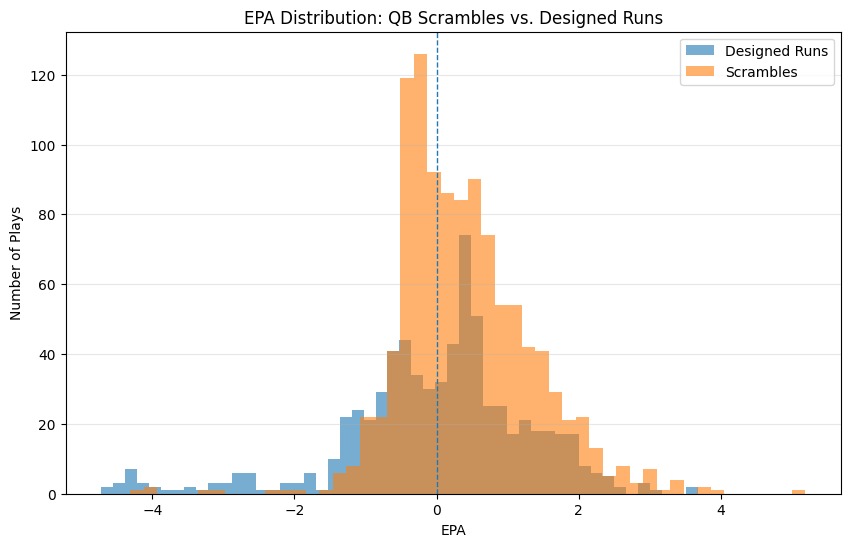

In [54]:
plt.figure(figsize=(10, 6))

plt.hist(
    validation_data.loc[
        validation_data["qb_scramble"].eq(0) &
        validation_data["play_type"].eq("run"),
        "qb_epa"
    ],
    bins=50,
    alpha=0.6,
    label="Designed Runs"
)

plt.hist(
    validation_data.loc[
        validation_data["qb_scramble"].eq(1),
        "qb_epa"
    ],
    bins=50,
    alpha=0.6,
    label="Scrambles"
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.title("EPA Distribution: QB Scrambles vs. Designed Runs")
plt.xlabel("EPA")
plt.ylabel("Number of Plays")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

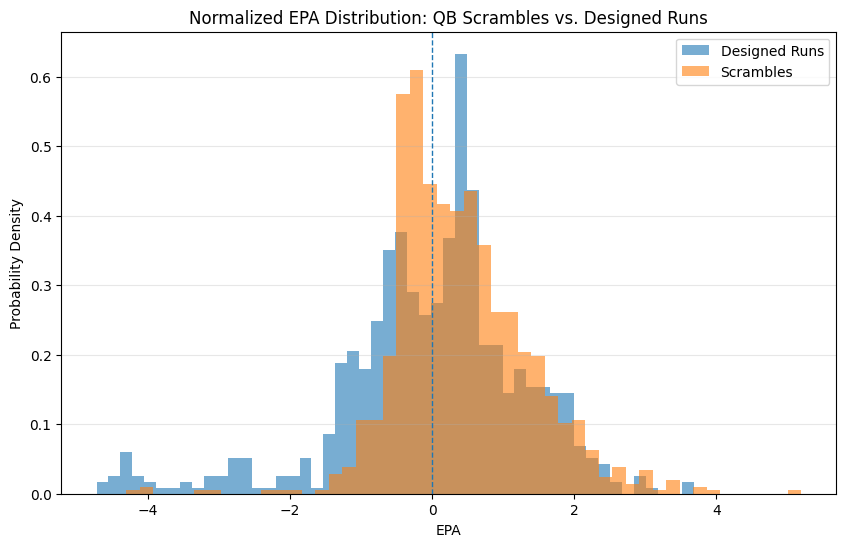

In [55]:
plt.figure(figsize=(10, 6))

designed_runs = validation_data.loc[
    validation_data["play_type"].eq("run") &
    validation_data["qb_scramble"].eq(0),
    "qb_epa"
]

scrambles = validation_data.loc[
    validation_data["qb_scramble"].eq(1),
    "qb_epa"
]

plt.hist(
    designed_runs,
    bins=50,
    density=True,
    alpha=0.6,
    label="Designed Runs"
)

plt.hist(
    scrambles,
    bins=50,
    density=True,
    alpha=0.6,
    label="Scrambles"
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.title("Normalized EPA Distribution: QB Scrambles vs. Designed Runs")
plt.xlabel("EPA")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()